# Анализ спроса на прокат велосипедов в Сеуле

Исходный анализ Михаила дополнен матрицей корреляций и двумя диаграммами рассеяния. Результаты рассчитаны по 8760 часовым наблюдениям. Запускайте ячейки по порядку. Ноутбук читает CSV из рабочей папки или загружает его из репозитория команды. Все изображения сохраняются в папку figures.

datetime64[us]
Start date: 2017-12-01 00:00:00
End date: 2018-11-30 00:00:00
Unique dates: 365
       count  nunique    min    max
count 365.00   365.00 365.00 365.00
mean   24.00    24.00   0.00  23.00
std     0.00     0.00   0.00   0.00
min    24.00    24.00   0.00  23.00
25%    24.00    24.00   0.00  23.00
50%    24.00    24.00   0.00  23.00
75%    24.00    24.00   0.00  23.00
max    24.00    24.00   0.00  23.00
Days with != 24 observations: 0
Days with != 24 unique hours: 0
Missing dates: 0
count   8760.00
mean     704.60
std      645.00
min        0.00
25%      191.00
50%      504.50
75%     1065.25
max     3556.00
Name: Rented Bike Count, dtype: float64

Zero rentals: 295

Negative rentals: 0

Functioning Day distribution:
Functioning Day
Yes    8465
No      295
Name: count, dtype: int64
                 count   mean  median  min   max      sum
Functioning Day                                          
No                 295   0.00    0.00    0     0        0
Yes               846

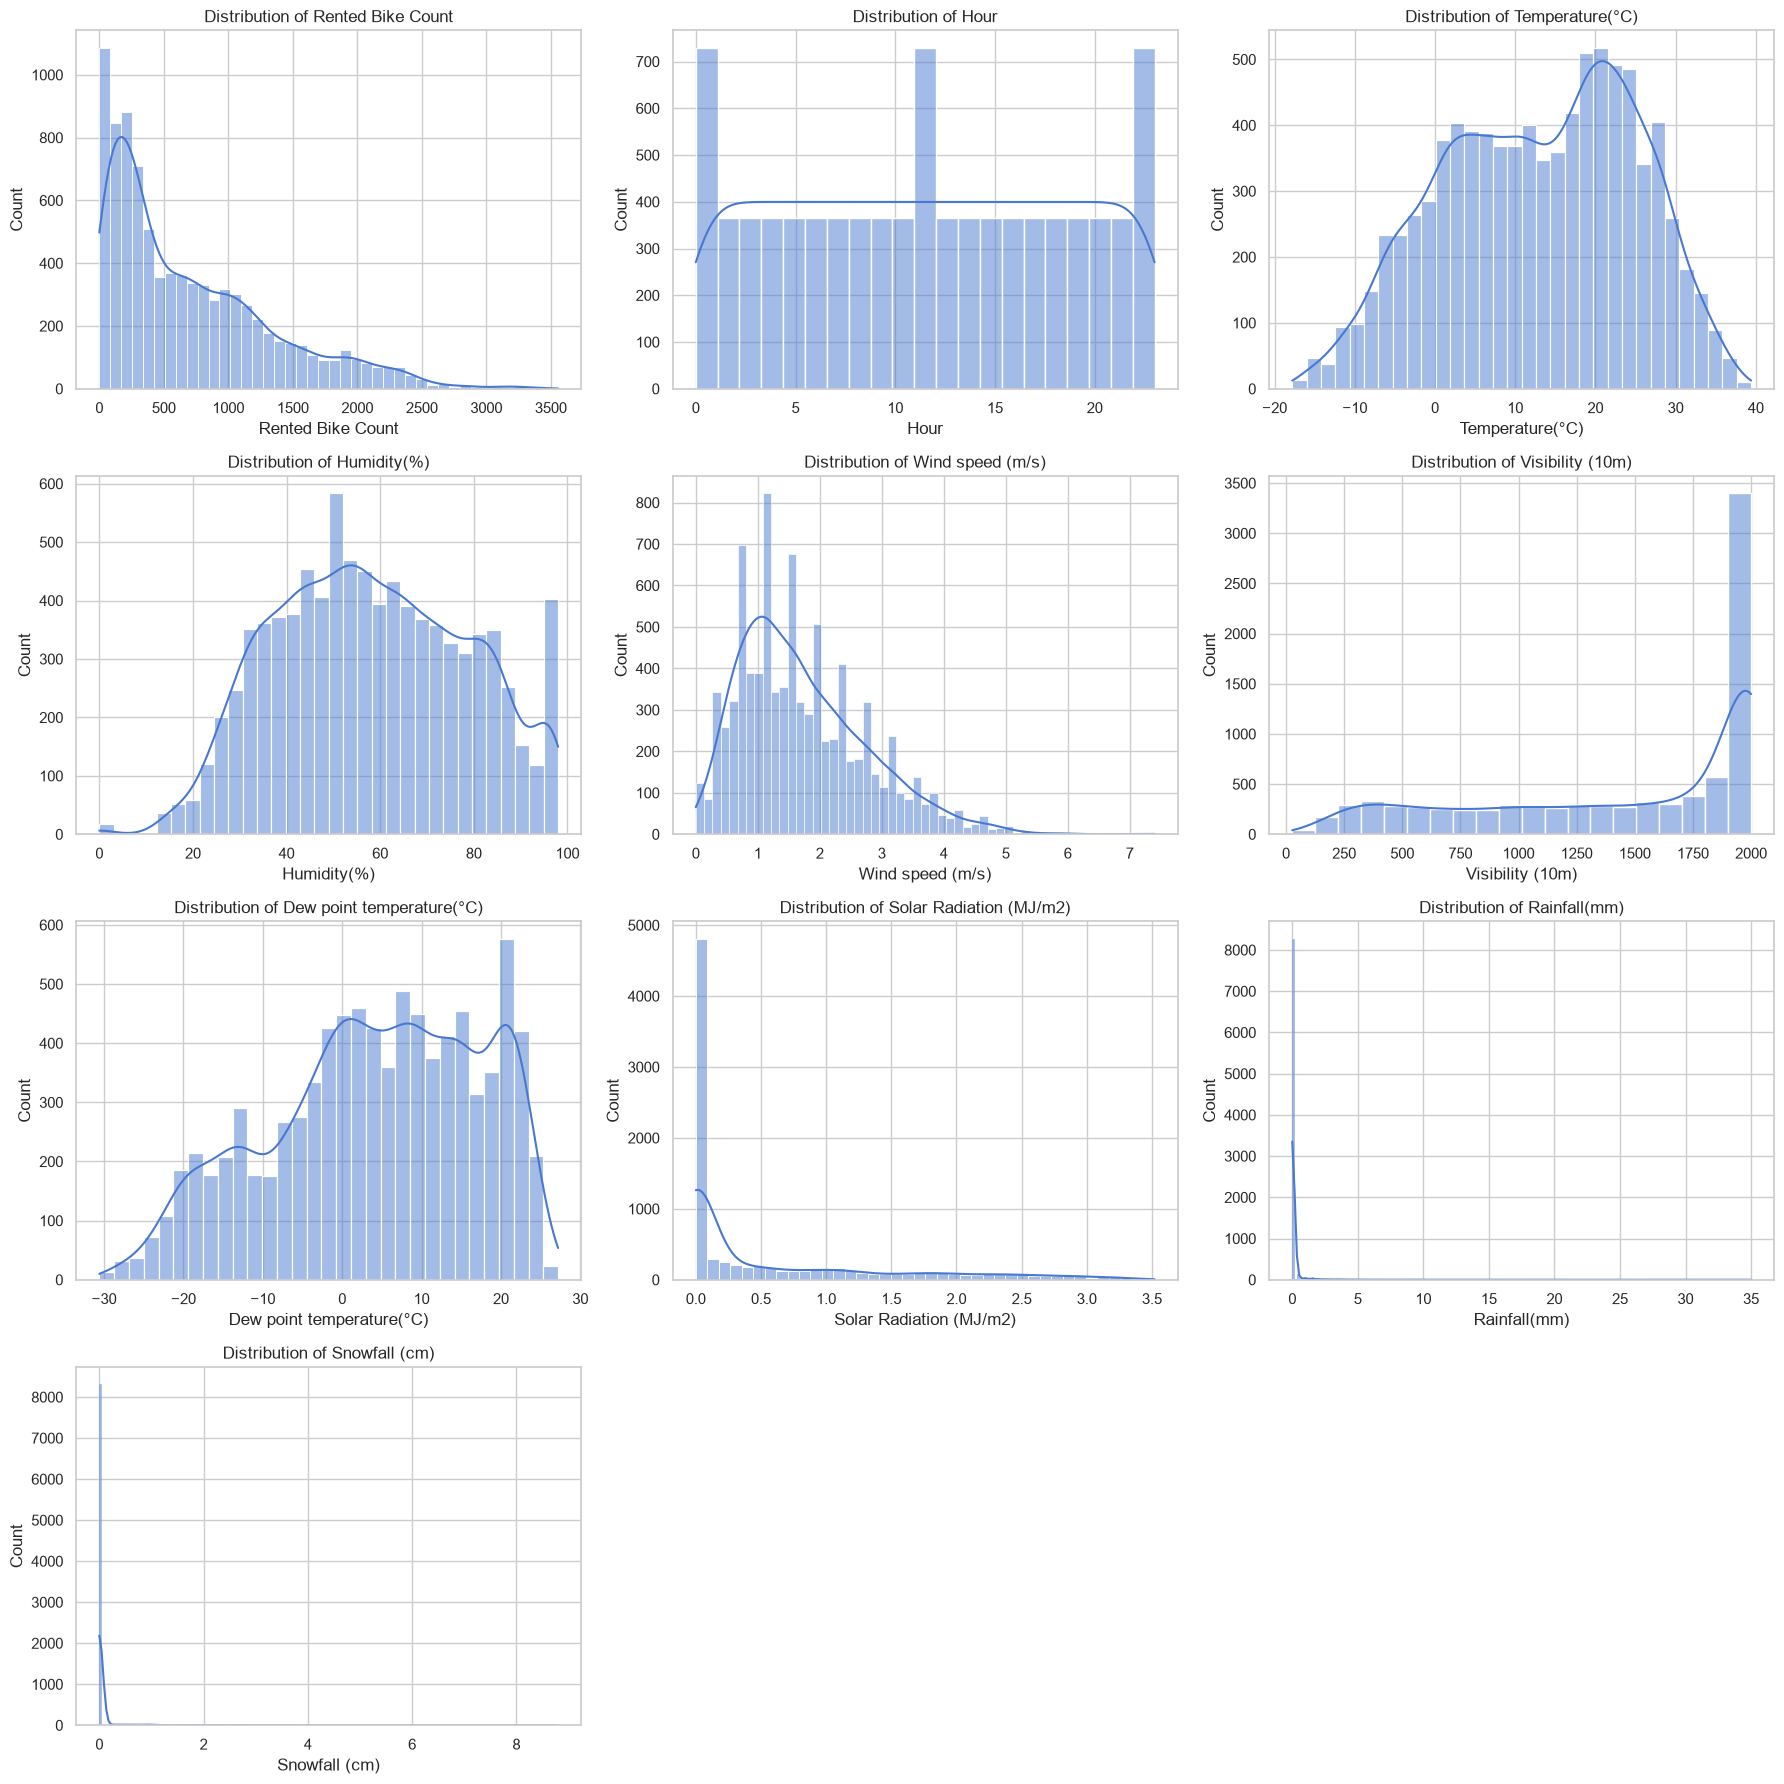

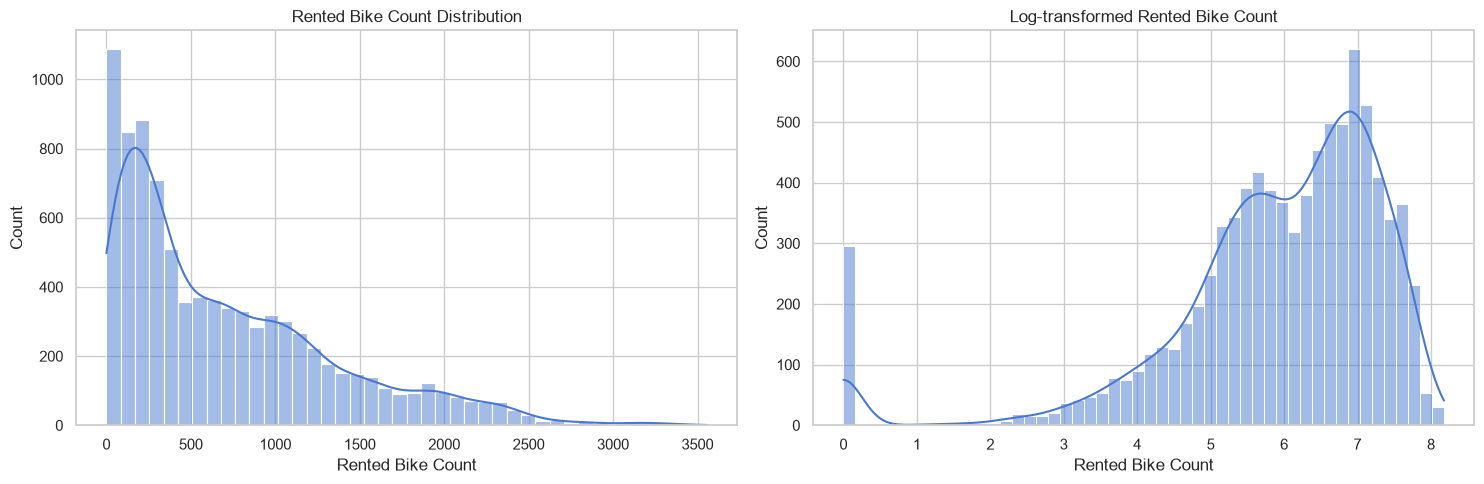

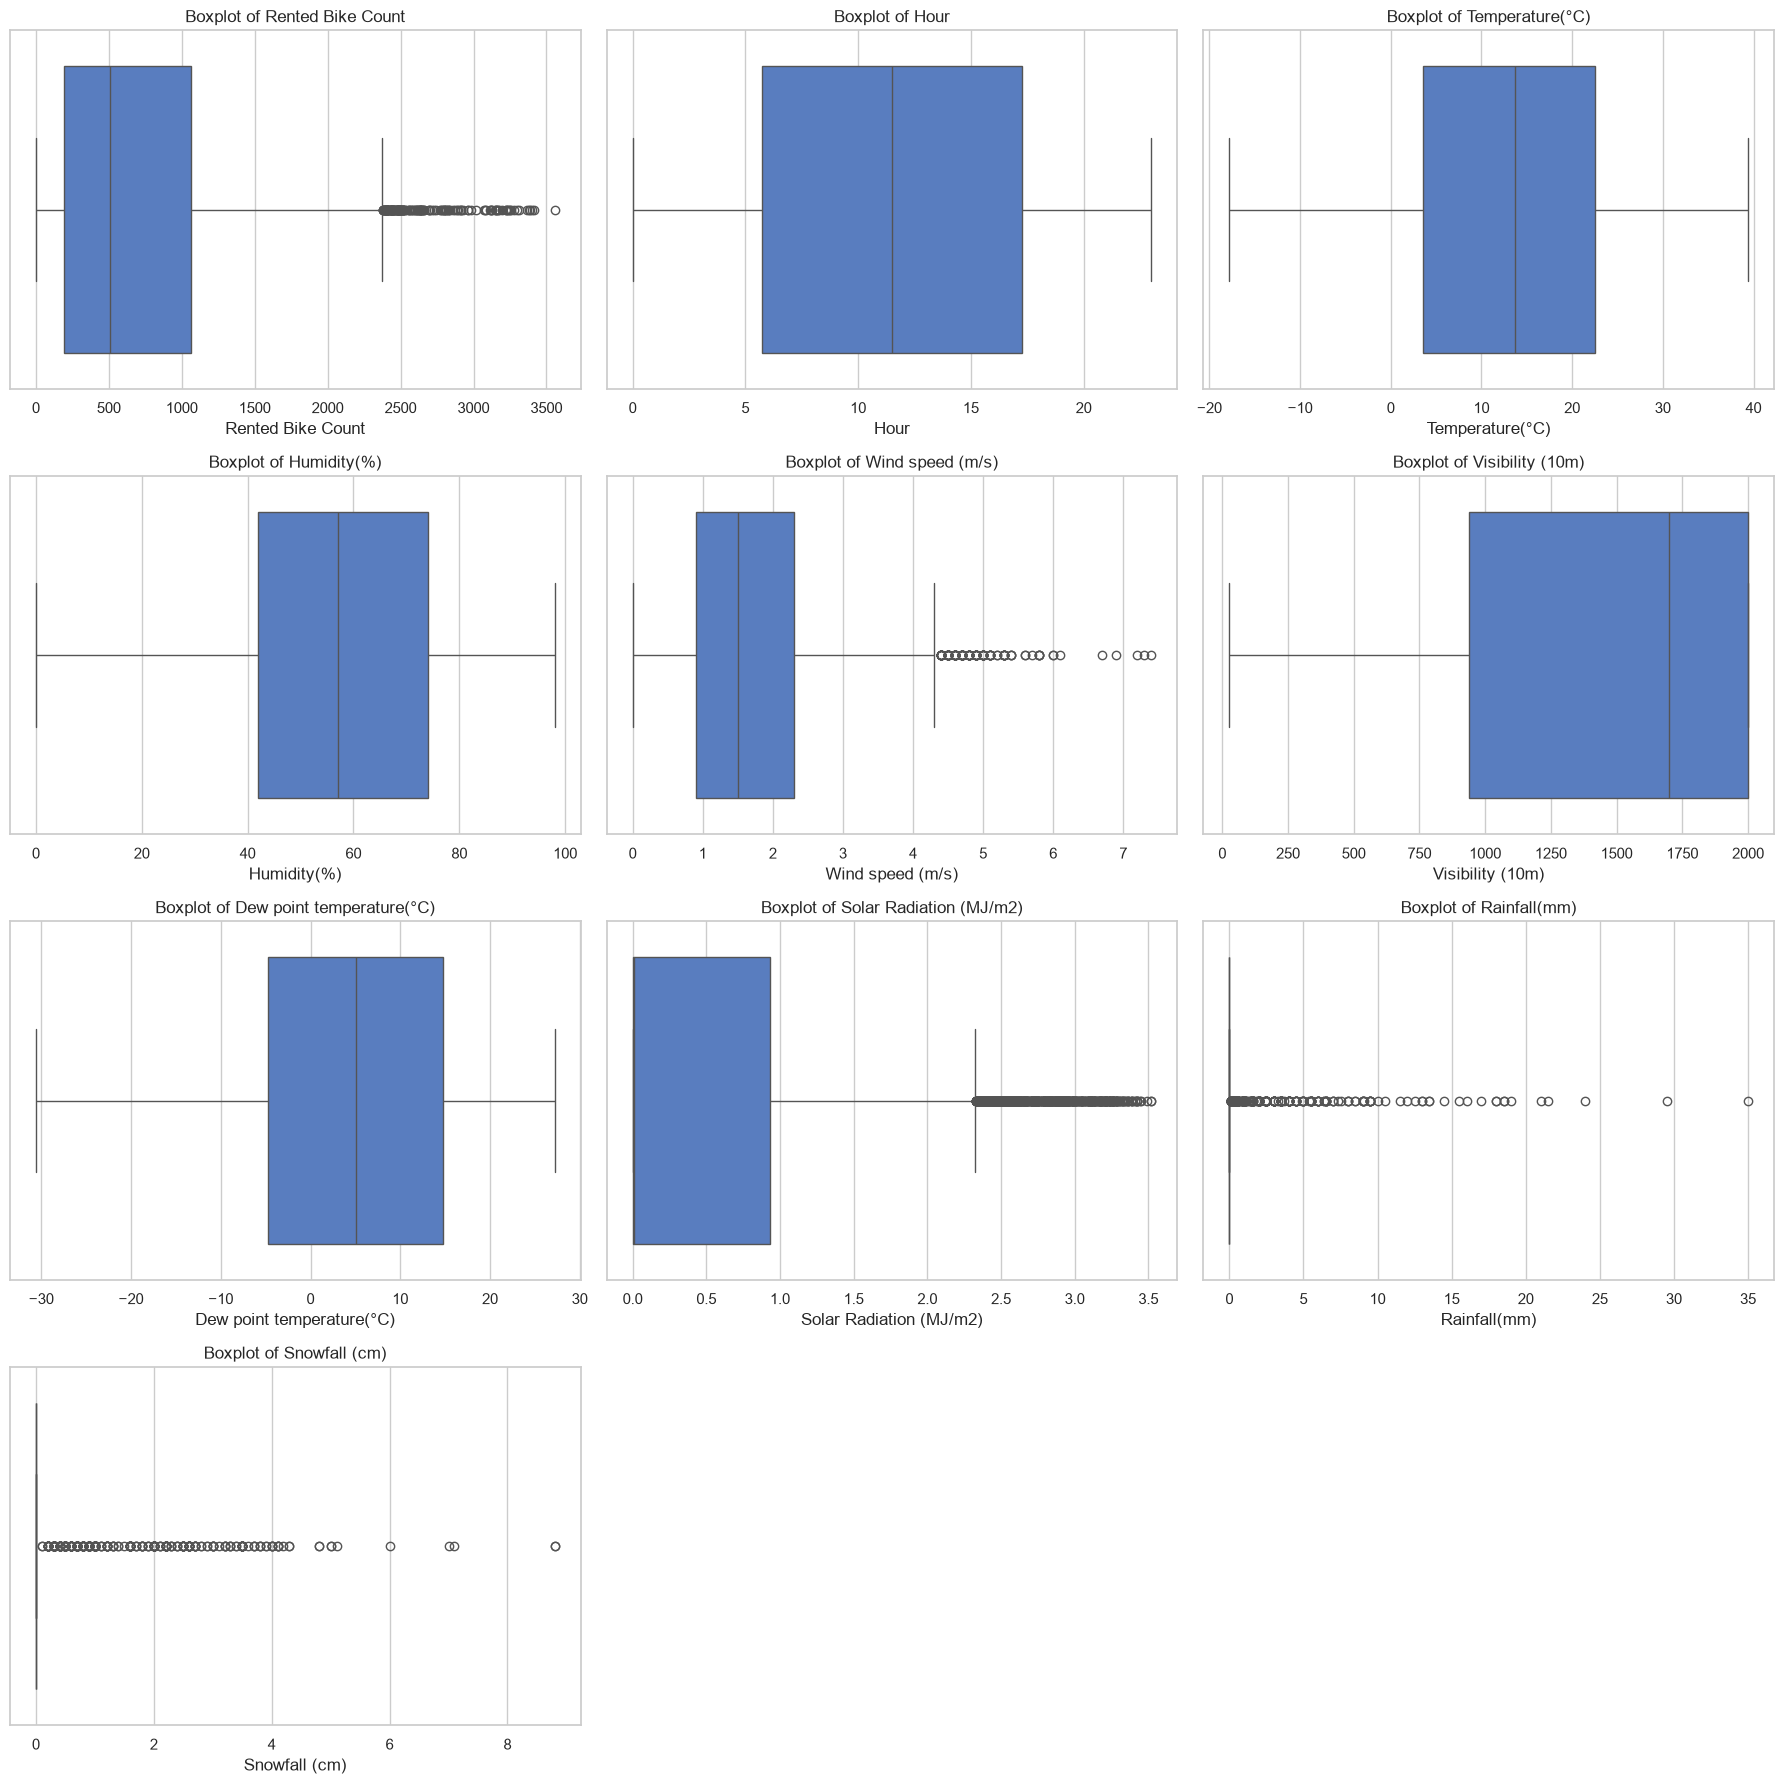

Rainfall(mm): 8232 zeros (93.97%)
Snowfall (cm): 8317 zeros (94.94%)
Solar Radiation (MJ/m2): 4300 zeros (49.09%)


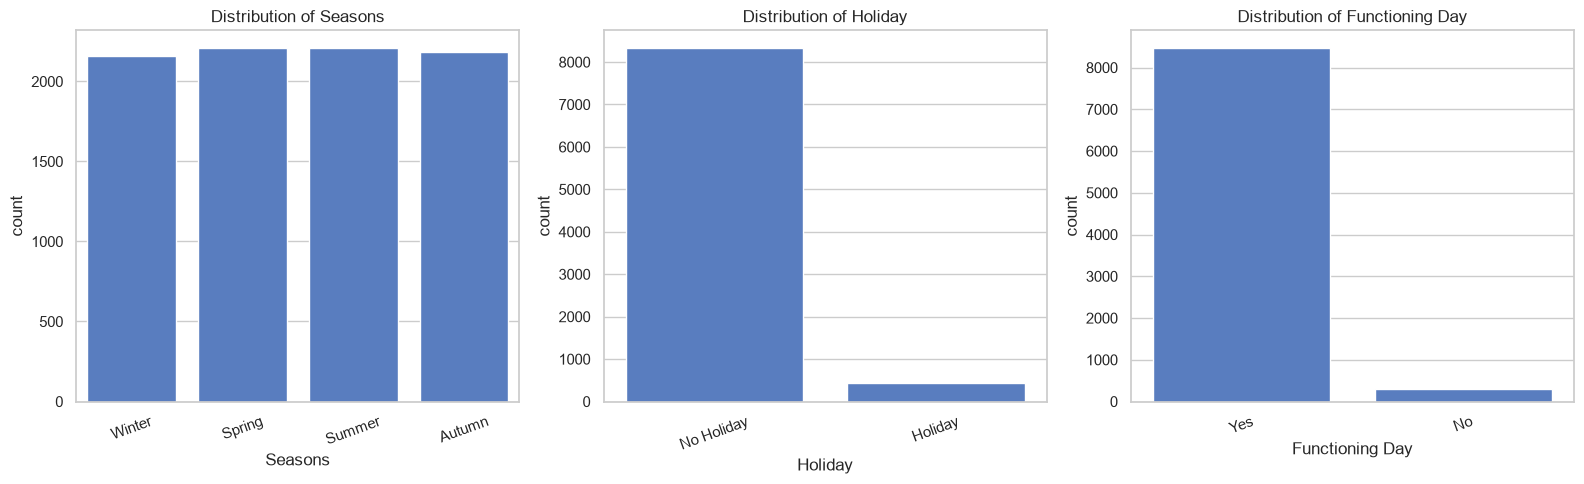

In [1]:
from pathlib import Path

FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)

data_file = Path("SeoulBikeData.csv")
data_source = data_file if data_file.exists() else "https://raw.githubusercontent.com/mikhail-balandin/Seoul-Bike-Sharing-Demand-Prediction/9e15a535a98d41d2c5dc6333be975926969e9206/SeoulBikeData.csv"
df = pd.read_csv(data_source, encoding="latin1")

# 1 EDA
# print(f'Df Shape: {df.shape}\n')
# print(df.head(10))

# df.info()

# print(df.describe(include='all').T)

# print('Columns:')
# print(df.columns.tolist())

# print('\nData types:')
# print(df.dtypes)

# print(f'Number of rows: {len(df)}')
# print(f'Number of columns: {len(df.columns)}')

# print(f'\nMemory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

# print(f'\nMissing values: {df.isna().sum().sum()}')
# print(f'Duplicated rows: {df.duplicated().sum()}')

# 2 Проверка качества данных

df['Date'] = pd.to_datetime(
    df['Date'],
    format='%d/%m/%Y'
)

print(df['Date'].dtype)
print(f"Start date: {df['Date'].min()}")
print(f"End date: {df['Date'].max()}")
print(f"Unique dates: {df['Date'].nunique()}")

# проверяем полноту временного ряда

daily_counts = df.groupby('Date')['Hour'].agg(
    ['count', 'nunique', 'min', 'max']
)

print(daily_counts.describe())

print("Days with != 24 observations:",
      (daily_counts['count'] != 24).sum())

print("Days with != 24 unique hours:",
      (daily_counts['nunique'] != 24).sum())

print("Missing dates:",
      365 - df['Date'].nunique())

# проверяем целевую переменную

print(df['Rented Bike Count'].describe())

print("\nZero rentals:",
      (df['Rented Bike Count'] == 0).sum())

print("\nNegative rentals:",
      (df['Rented Bike Count'] < 0).sum())

print("\nFunctioning Day distribution:")
print(df['Functioning Day'].value_counts())


print(
    df.groupby('Functioning Day')['Rented Bike Count']
    .agg(['count', 'mean', 'median', 'min', 'max', 'sum'])
)

categorical_columns = [
    'Seasons',
    'Holiday',
    'Functioning Day'
]

for col in categorical_columns:
    print(f'\n{col}')
    print(df[col].value_counts())
    print('Unique:', df[col].unique())

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:
    print(f'\n{col}')
    print(f'Min: {df[col].min()}')
    print(f'Max: {df[col].max()}')
    print(f'Negative values: {(df[col] < 0).sum()}')

# 3 визуальное исследование

# распределение числовых признаков

numeric_columns = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(f'Distribution of {col}')

for i in range(len(numeric_columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_distributions.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# целевая переменная

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    df['Rented Bike Count'],
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Rented Bike Count Distribution')

sns.histplot(
    np.log1p(df['Rented Bike Count']),
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Log-transformed Rented Bike Count')

plt.tight_layout()
fig.savefig(FIGURES_DIR / "02_rentals.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# поиск выбросов

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.flatten()

for i, col in enumerate(numeric_columns):
    sns.boxplot(
        data=df,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(f'Boxplot of {col}')

for i in range(len(numeric_columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "03_boxplots.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# анализ нулевых значений осадков
weather_columns = [
    'Rainfall(mm)',
    'Snowfall (cm)',
    'Solar Radiation (MJ/m2)'
]

for col in weather_columns:
    zero_count = (df[col] == 0).sum()
    zero_percent = zero_count / len(df) * 100

    print(
        f'{col}: {zero_count} zeros '
        f'({zero_percent:.2f}%)'
    )


# канализ категориальных переменных
categorical_columns = [
    'Seasons',
    'Holiday',
    'Functioning Day'
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, col in enumerate(categorical_columns):
    sns.countplot(
        data=df,
        x=col,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=20)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "04_categories.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

## Матрица корреляций

Матрица показывает линейную связь между числовыми показателями. Используется коэффициент Пирсона на всех 8760 наблюдениях, включая часы, когда прокат не работал. Пропусков в выбранных числовых столбцах нет.

| Значение | Как читать |
|---|---|
| Близко к +1, красный цвет | Большие значения одного показателя обычно связаны с большими значениями другого |
| Близко к -1, синий цвет | Большие значения одного показателя обычно связаны с меньшими значениями другого |
| Близко к 0, светлый цвет | Слабая линейная связь; нелинейная связь при этом возможна |
| 1 на диагонали | Показатель сравнивается с самим собой |

Выберите строку одного показателя и столбец другого: число на пересечении и есть их корреляция. Верхняя и нижняя половины матрицы повторяют друг друга. Дата, сезон, праздник и статус работы не включены: они не являются числовыми столбцами в этой таблице.

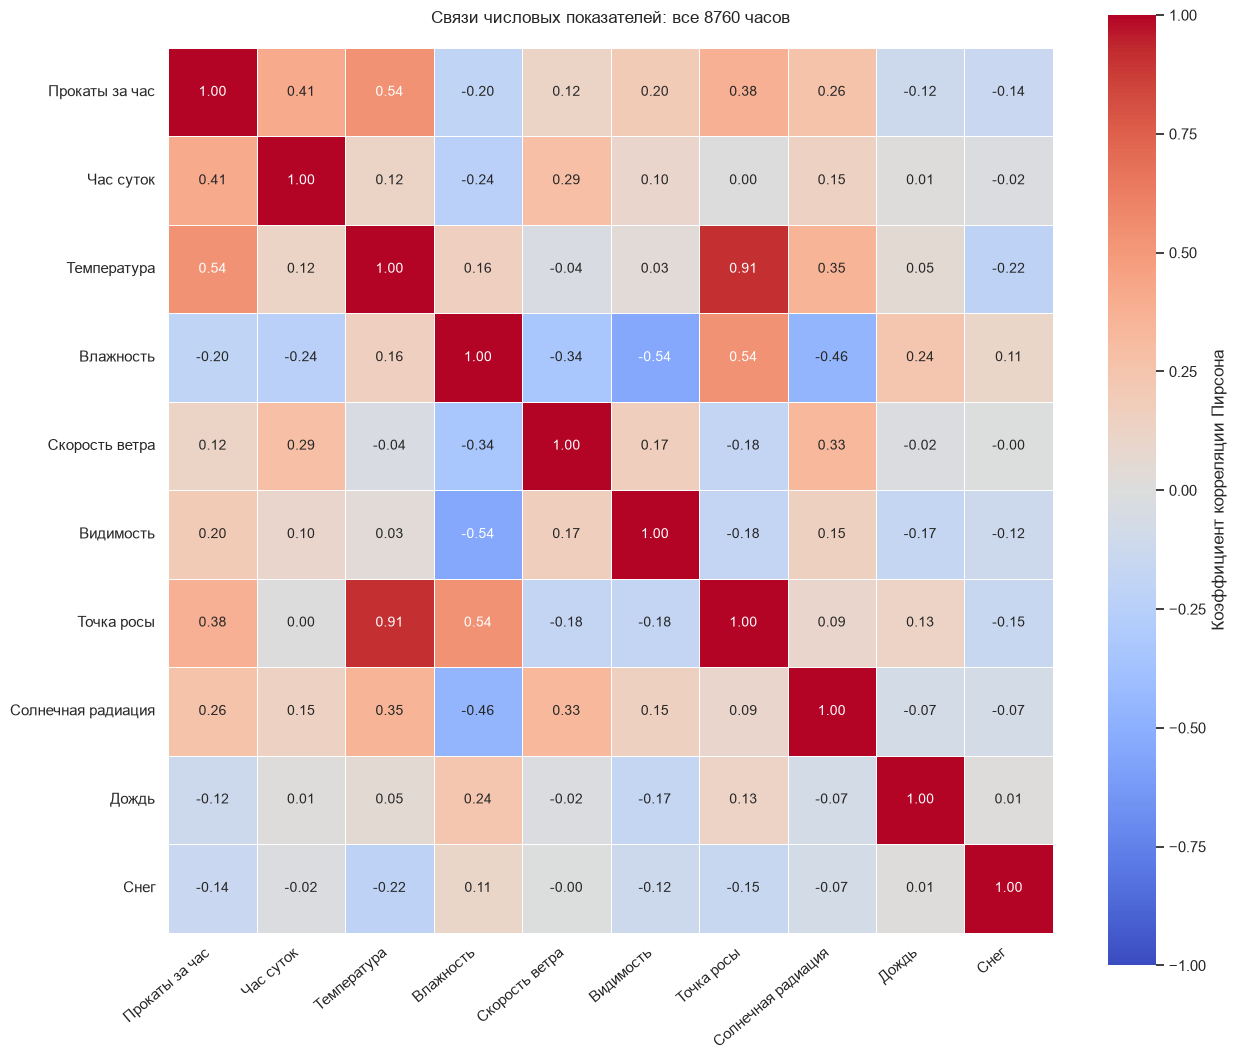

,Корреляция с количеством прокатов
Температура,0.54
Час суток,0.41
Точка росы,0.38
Солнечная радиация,0.26
Влажность,-0.20
Видимость,0.20
Снег,-0.14
Дождь,-0.12
Скорость ветра,0.12


In [2]:
# Матрица корреляций. Автор кода: Никита Саралашвили.
# Корреляции считаются по числовым столбцам; исходный df не меняется.
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr(method="pearson")

labels = {
    "Rented Bike Count": "Прокаты за час",
    "Hour": "Час суток",
    "Humidity(%)": "Влажность",
    "Wind speed (m/s)": "Скорость ветра",
    "Visibility (10m)": "Видимость",
    "Solar Radiation (MJ/m2)": "Солнечная радиация",
    "Rainfall(mm)": "Дождь",
    "Snowfall (cm)": "Снег",
}
for column in corr.columns:
    if column.startswith("Temperature("):
        labels[column] = "Температура"
    elif column.startswith("Dew point temperature("):
        labels[column] = "Точка росы"

corr_named = corr.rename(index=labels, columns=labels)
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(
    corr_named, annot=True, fmt=".2f", cmap="coolwarm",
    vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
    annot_kws={"size": 10},
    cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=ax,
)
ax.set_title("Связи числовых показателей: все 8760 часов", pad=18)
plt.xticks(rotation=40, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig(FIGURES_DIR / "05_correlations.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Связи со спросом, от наиболее заметных по модулю к наименее заметным.
demand_corr = corr_named["Прокаты за час"].drop("Прокаты за час")
demand_corr = demand_corr.reindex(demand_corr.abs().sort_values(ascending=False).index)
display(demand_corr.round(3).to_frame("Корреляция с количеством прокатов"))


## Что показывает матрица

| Пара показателей | Корреляция, округлённо | Вывод по этим данным |
|---|---:|---|
| Температура и прокаты | +0,54 | В более тёплые часы обычно больше прокатов. Это наиболее заметная линейная связь со спросом среди выбранных показателей |
| Час суток и прокаты | +0,41 | Есть положительная связь с номером часа, но она не описывает суточные пики. Часы цикличны: 23:00 и 00:00 соседние. Нужен отдельный график спроса по часам |
| Точка росы и прокаты | +0,38 | Есть положительная связь; часть её может быть связана с температурой |
| Солнечная радиация и прокаты | +0,26 | Положительная линейная связь сравнительно небольшая |
| Влажность и прокаты | -0,20 | Более высокая влажность связана с меньшим спросом, но линейная связь слабая |
| Видимость и прокаты | +0,20 | При большей видимости прокатов обычно немного больше; связь слабая |
| Снег и прокаты | -0,14 | Слабая отрицательная линейная связь; это не доказывает отсутствие существенного влияния снега в отдельных условиях |
| Дождь и прокаты | -0,12 | Слабая отрицательная линейная связь. Нулевых осадков много, поэтому полезно отдельно сравнить часы с дождём и без него |
| Скорость ветра и прокаты | +0,12 | Очень слабая положительная связь; нельзя заключать, что ветер увеличивает спрос |
| Температура и точка росы | +0,91 | Очень сильная положительная связь. Признаки несут частично похожую информацию; в линейной модели стоит проверить мультиколлинеарность |
| Влажность и видимость | -0,54 | Более высокая влажность связана с меньшей видимостью |

Корреляция не доказывает причинность. Например, температура меняется вместе с сезоном и временем суток. Эти расчёты не отделяют действие одного фактора от остальных.

Низкая корреляция не означает бесполезность признака: связь может быть нелинейной. Не нужно автоматически удалять дождь, снег или ветер. Температуру и точку росы тоже не следует удалять только по матрице: полезность проверяется на выбранной модели и отложенных по времени данных.

Расчёт включает часы, когда сервис не работал. Нулевые прокаты в такие часы отражают отсутствие обслуживания, а не обязательно отсутствие спроса. При подготовке модели нужно решить, прогнозируем ли мы фактические прокаты или спрос при работающем сервисе, и отдельно сравнить связи для часов работы.

Следующий шаг: построить средние прокаты по часам, сравнить спрос по сезонам и при наличии осадков, затем обучить базовую модель. Матрица корреляций сама по себе не является моделью и не оценивает точность прогноза.

## Прямая и обратная связь

Каждая точка соответствует одному часу. Температура и прокаты показывают положительную корреляцию (+0,54), влажность и видимость показывают отрицательную (−0,54).

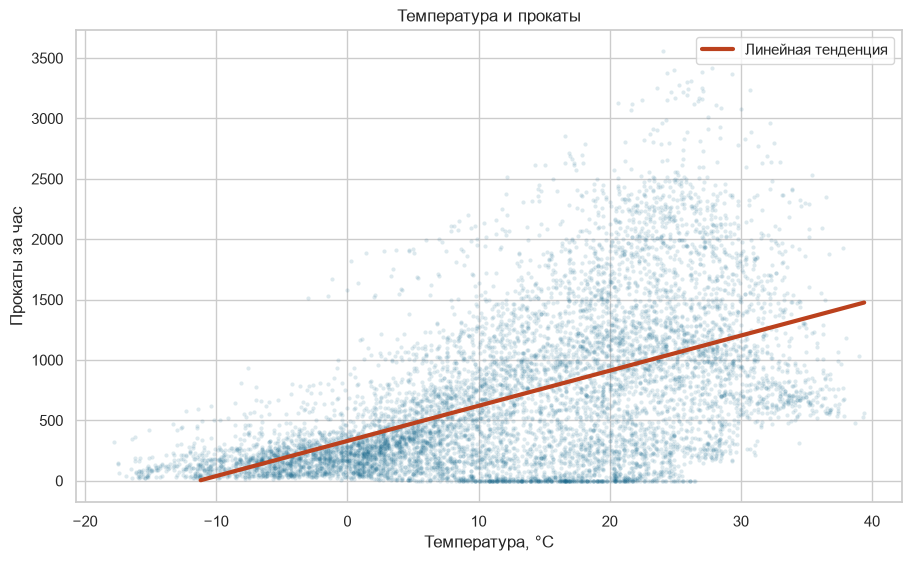

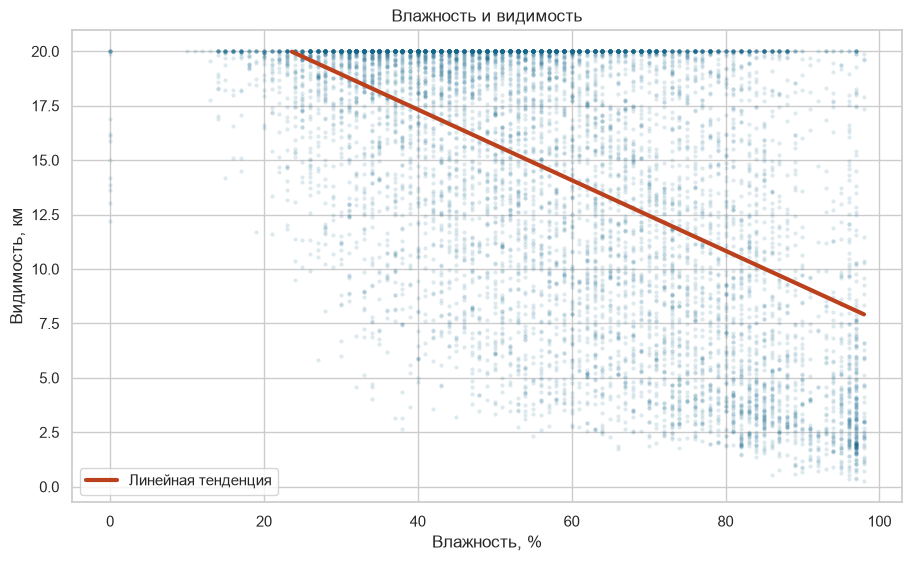

In [3]:
def plot_pair(x, y, xlabel, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
    ax.scatter(x, y, s=9, color="#15668b", alpha=0.14, linewidths=0)
    slope, intercept = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 200)
    ys = slope * xs + intercept
    visible = (ys >= y.min()) & (ys <= y.max())
    ax.plot(xs[visible], ys[visible], color="#bb411d", lw=3, label="Линейная тенденция")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend()
    fig.savefig(FIGURES_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

plot_pair(df["Temperature(°C)"], df["Rented Bike Count"],
          "Температура, °C", "Прокаты за час", "Температура и прокаты",
          "06_temperature_rentals.png")
plot_pair(df["Humidity(%)"], df["Visibility (10m)"] / 100,
          "Влажность, %", "Видимость, км", "Влажность и видимость",
          "07_humidity_visibility.png")

## Общий рисунок для отчёта

Семь графиков в одном PNG. Изображения в исходном размере доступны в папке figures.

In [4]:
from PIL import Image

panels = [
    ("01_distributions.png", "Распределения числовых показателей"),
    ("03_boxplots.png", "Разброс и крайние значения"),
    ("02_rentals.png", "Распределение прокатов"),
    ("04_categories.png", "Сезоны, праздники и работа проката"),
    ("05_correlations.png", "Корреляции числовых показателей"),
    ("06_temperature_rentals.png", "Температура и прокаты"),
    ("07_humidity_visibility.png", "Влажность и видимость"),
]
fig = plt.figure(figsize=(18, 27), layout="constrained")
grid = fig.add_gridspec(4, 2, height_ratios=[9, 3.3, 8, 5])
positions = [grid[0, 0], grid[0, 1], grid[1, 0], grid[1, 1],
             grid[2, :], grid[3, 0], grid[3, 1]]
for (filename, title), position in zip(panels, positions):
    ax = fig.add_subplot(position)
    with Image.open(FIGURES_DIR / filename) as panel:
        panel.thumbnail((1900, 1750), Image.Resampling.LANCZOS)
        ax.imshow(panel)
    ax.set_title(title, fontsize=14)
    ax.axis("off")
fig.suptitle("Прокат велосипедов в Сеуле | 8760 часовых наблюдений", fontsize=22)
fig.savefig(FIGURES_DIR / "00_overview.png", dpi=180, facecolor="white")
plt.close(fig)